# 01 · Problem Framing and Dataset Preparation
**Capstone: Intelligent Retail Decision Assistant**, IITM Pravartak, Professional Certificate Programme in Generative AI and Machine Learning

## Business use case
A mid-sized online fashion retailer (shoes, apparel, accessories) wants one assistant that serves two audiences:

| Audience | Business question | Component that answers it |
|---|---|---|
| Merchandising / growth team | *Which product views are likely to convert, and what drives conversion?* | Supervised ML: predict `purchase_flag` (notebook 02) |
| CRM / marketing team | *What customer segments do we have, and which ones respond to discounts?* | Unsupervised ML: RFM segmentation + price sensitivity (02) |
| Shoppers | *Find me a product that fits my need and budget* | RAG product recommendation (03) |
| Shoppers / support | *Can I return / exchange / get a refund...?* | Grounded policy QA with citations (04) |
| Everyone | *One entry point that picks the right tool* | Agent / controller with a visible trace (05) |

In [1]:
# --- setup: make the project package importable and show the run mode ---
import sys, os, json, warnings
from pathlib import Path
# library deprecation notices print install paths; hide them here and in parallel worker processes
os.environ["PYTHONWARNINGS"] = "ignore"; warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import src                                   # sets macOS OpenMP compatibility flags
from src import config
from src.llm import mode_label
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid", palette="Set2"); plt.rcParams["figure.dpi"] = 110
OUT = config.OUTPUTS
print("Mode:", mode_label(), "| outputs ->", OUT.relative_to(ROOT))

Mode: LIVE (gpt-4o-mini + text-embedding-3-small) | outputs -> outputs


## 1. Load the course dataset and policies

In [2]:
from src import data_prep
raw = data_prep.load_raw()
policies = data_prep.load_policies()
print(raw.shape, "| policies:", list(policies))
raw.head(3).T

(1500, 46) | policies: ['POL_RETURNS', 'POL_EXCHANGE', 'POL_SHIPPING', 'POL_REFUND', 'POL_WARRANTY']


,0,1,2
customer_id,C100,C101,C102
age,26,45,54
gender,Male,Female,Male
city_tier,Tier-3,Tier-2,Tier-3
state,Tamil Nadu,Maharashtra,Delhi
income_band,Low,Low,Low
occupation,Self-Employed,Teacher,Engineer
membership_level,Platinum,Bronze,Gold
days_since_last_purchase,42,23,24
avg_order_value,3334.08,4151.07,2609.11


## 2. Schema, missing values and targets

In [3]:
schema = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(), "unique": raw.nunique()})
schema

,dtype,missing,unique
customer_id,str,0,250
age,int64,0,43
gender,str,0,2
city_tier,str,0,3
state,str,0,5
income_band,str,0,3
occupation,str,0,5
membership_level,str,0,4
days_since_last_purchase,int64,0,110
avg_order_value,float64,0,1491


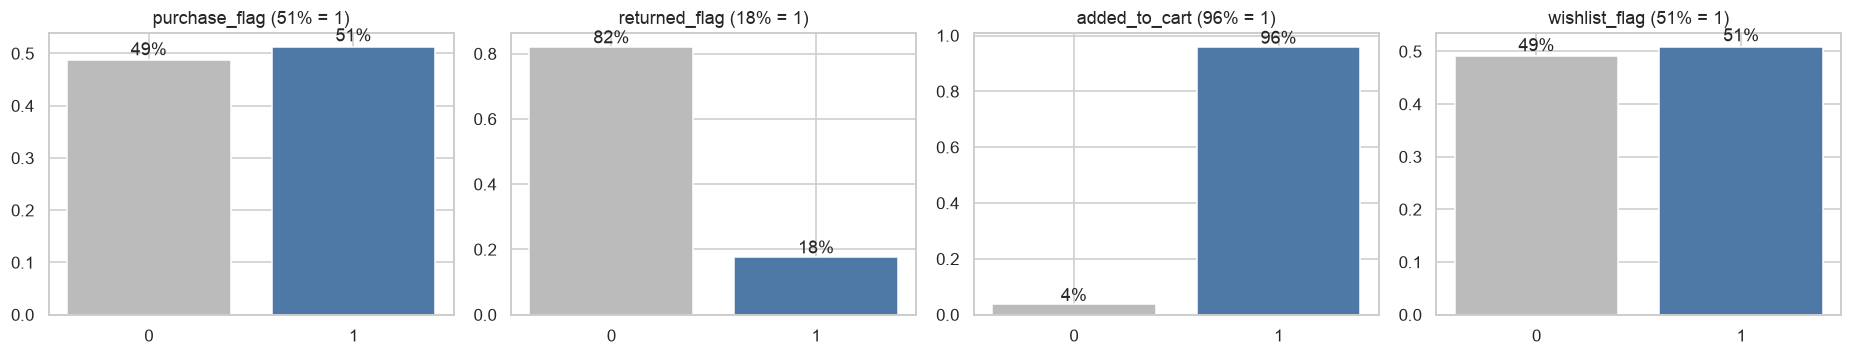

returned_flag     0    1   All
purchase_flag                 
0               730    0   730
1               503  267   770
All            1233  267  1500


In [4]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.4))
for ax, col in zip(axes, ["purchase_flag", "returned_flag", "added_to_cart", "wishlist_flag"]):
    vc = raw[col].value_counts(normalize=True).sort_index()
    ax.bar(vc.index.astype(str), vc.values, color=["#bbb", "#4e79a7"]); ax.set_title(f"{col} ({vc.get(1, 0):.0%} = 1)")
    for i, v in enumerate(vc.values): ax.text(i, v + 0.01, f"{v:.0%}", ha="center")
plt.tight_layout(); plt.savefig(OUT / "01_targets.png"); plt.show()
print(pd.crosstab(raw.purchase_flag, raw.returned_flag, margins=True))

- **`purchase_flag` is balanced** (51% / 49%), so accuracy is meaningful. We still report ROC-AUC and PR-AUC, and no resampling is needed.
- **`returned_flag` = 1 only happens after a purchase.** The crosstab shows 0 returns among non-purchases, so it is a post-purchase outcome and must never be a feature for predicting purchases.
- `added_to_cart` is 96% ones, so it carries little information on its own.

## 3. Data audit: findings that change the design

In [5]:
audit = data_prep.audit(raw)
pd.Series({k: v for k, v in audit.items()}, name="value").to_frame()

,value
rows,1500
columns,46
missing,{'size': 270}
duplicate_rows,0
rows_per_product_id,5
product_ids_with_conflicting_category,295
product_ids_with_conflicting_brand,300
rows_per_customer_id,6
customer_ids_with_conflicting_age,250
size_missing_share_by_category,"{'Accessories': 0.181, 'Apparel': 0.174, 'Shoes': 0.185}"


In [6]:
print(raw[raw.product_id == "P1000"][["product_id", "category", "sub_category", "brand", "color", "final_price"]])
print()
print(raw[raw.customer_id == "C100"][["customer_id", "age", "gender", "membership_level", "income_band"]])

     product_id     category sub_category      brand  color  final_price
0         P1000  Accessories     Backpack   Fastrack   Blue      3478.35
300       P1000  Accessories       Wallet  Wildcraft  Green      3746.65
600       P1000      Apparel       Tshirt   Roadster  Olive      1845.48
900       P1000      Apparel        Jeans       Zara  Black       349.30
1200      P1000      Apparel        Shirt     Uniqlo  Olive      2990.22

     customer_id  age  gender membership_level income_band
0           C100   26    Male         Platinum         Low
250         C100   21    Male           Bronze        High
500         C100   42  Female             Gold        High
750         C100   29    Male             Gold        High
1000        C100   25  Female         Platinum      Medium
1250        C100   19    Male             Gold      Medium


**What the audit shows, and the decisions taken:**
1. **`product_id` is not a product key.** Every id appears in exactly 5 rows, and the rows describe completely different products (295 of 300 ids even have conflicting categories). → We treat each row's product as its own catalogue item and add a stable key **`item_id`** (`ITM0000`-`ITM1499`). The original `product_id` is kept for traceability.
2. **`customer_id` is not a customer key either.** Each id has 6 rows with different ages, genders and membership levels. → Customer analysis is done at the **interaction level** (one row = one customer-product interaction, with the customer attributes as recorded for that interaction). We do not aggregate by `customer_id`, because that would average unrelated people.
3. **`size` is missing in 270 rows (18%), spread evenly across all categories** (about 17-18% each). It is not a structural "accessories have no size" pattern. → Filled with an explicit `Unknown` category, plus a `size_missing` flag, so the model can learn whether missingness matters.
4. **Leakage:** `returned_flag`, `rating_given` (a rating of 5 appears only for purchasers), `review_sentiment_label` and `customer_review_text` are post-purchase. `payment_mode`, `delivery_type` and `quantity` are chosen at checkout. → All are excluded from the purchase model (details in notebook 02).
5. **No duplicate rows.** Prices are consistent: `final_price` = `base_price` × (1 − discount).

In [7]:
chk = (raw.base_price * (1 - raw.discount_percent / 100) - raw.final_price).abs()
print(f"max |base_price*(1-discount) - final_price| = {chk.max():.2f} INR")

max |base_price*(1-discount) - final_price| = 0.01 INR


## 4. Clean and engineer

In [8]:
df = data_prep.run()          # writes data/processed/retail_clean.csv + data_dictionary.csv
print(df.shape)
df[["item_id", "product_id", "size", "size_filled", "size_missing", "discount_amount", "price_to_aov",
    "income_ord", "membership_ord", "engagement", "price_band"]].head()

(1500, 55)


,item_id,product_id,size,size_filled,size_missing,discount_amount,price_to_aov,income_ord,membership_ord,engagement,price_band
0,ITM0000,P1000,XL,XL,0,0.00,1.0433,0,3,1,Mid
1,ITM0001,P1001,NaN,Unknown,1,484.16,0.2722,0,0,1,Budget
2,ITM0002,P1002,L,L,0,399.20,0.8670,0,2,1,Mid
3,ITM0003,P1003,NaN,Unknown,1,1105.29,0.8393,2,1,2,Mid
4,ITM0004,P1004,S,S,0,350.62,0.2342,2,2,2,Budget


| Engineered column | Why |
|---|---|
| `item_id` | stable product key (see audit finding 1) |
| `size_filled`, `size_missing` | explicit handling of the 18% missing sizes |
| `discount_amount` | money saved; a more direct price signal than the percentage alone |
| `price_to_aov` | is this item expensive *for this customer* (price ÷ their usual order value)? |
| `income_ord`, `membership_ord` | the order Low < Medium < High and Bronze < … < Platinum is real, so it is kept as numbers |
| `engagement` | `added_to_cart` + `wishlist_flag`, a simple intent score |
| `price_band` | Budget / Mid / Premium label, used in product text and filters |

## 5. Data dictionary: original vs engineered columns

In [9]:
dd = pd.read_csv(config.PROCESSED / "data_dictionary.csv")
print(dd["origin"].value_counts().to_string()); print()
dd

origin
original (course dataset)    46
engineered (this project)     9



,column,group,origin,dtype,missing,unique,example,description,how_created
0,customer_id,Customer profile,original (course dataset),str,0,250,C100,Customer identifier (NOT stable across rows - see data notes),NaN
1,age,Customer profile,original (course dataset),int64,0,43,26,Customer age in years,NaN
2,gender,Customer profile,original (course dataset),str,0,2,Male,Customer gender,NaN
3,city_tier,Customer profile,original (course dataset),str,0,3,Tier-3,Tier-1/2/3 city,NaN
4,state,Customer profile,original (course dataset),str,0,5,Tamil Nadu,Indian state,NaN
5,income_band,Customer profile,original (course dataset),str,0,3,Low,Low / Medium / High,NaN
6,occupation,Customer profile,original (course dataset),str,0,5,Self-Employed,Customer occupation,NaN
7,membership_level,Customer profile,original (course dataset),str,0,4,Platinum,Bronze < Silver < Gold < Platinum loyalty tier,NaN
8,days_since_last_purchase,Customer history,original (course dataset),int64,0,110,42,Recency: days since the customer's previous order,NaN
9,avg_order_value,Customer history,original (course dataset),float64,0,1491,3334.08,Customer's historical average order value (INR),NaN


**About the text columns.** The course dataset already includes the GenAI extension columns: `product_title`, `product_description`, `customer_review_text`, `customer_query`, `policy_doc_id`, `policy_text_snippet`, `style_tags`, `occasion_tags`, `recommended_use_case` and `image_path`. They are template-generated (for example only 28 distinct review texts, and image files are not supplied), so they are marked *original (course dataset)*. One small fix was applied: the title template cuts "Accessories" to "Accessorie", which was corrected for retrieval quality. The 5 policies in `retail_policies.json` are used as-is. **No policy text was invented.**

## 6. First look at conversion drivers

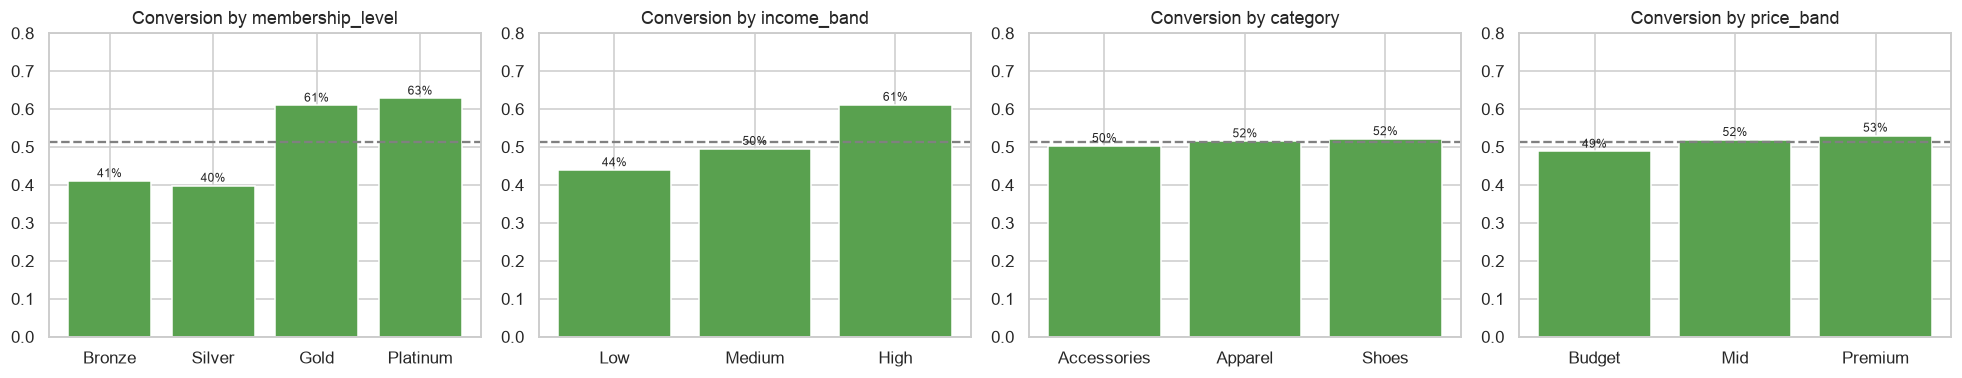

Conversion by product rating: {Interval(0.0, 3.0, closed='right'): 0.393, Interval(3.0, 3.5, closed='right'): 0.469, Interval(3.5, 4.0, closed='right'): 0.448, Interval(4.0, 5.0, closed='right'): 0.569}


In [10]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, col in zip(axes, ["membership_level", "income_band", "category", "price_band"]):
    order = {"membership_level": ["Bronze", "Silver", "Gold", "Platinum"], "income_band": ["Low", "Medium", "High"]}.get(col)
    r = df.groupby(col)["purchase_flag"].mean().reindex(order) if order else df.groupby(col)["purchase_flag"].mean()
    ax.bar(r.index.astype(str), r.values, color="#59a14f"); ax.axhline(df.purchase_flag.mean(), ls="--", c="grey")
    ax.set_title(f"Conversion by {col}"); ax.set_ylim(0, 0.8)
    for i, v in enumerate(r.values): ax.text(i, v + 0.01, f"{v:.0%}", ha="center", fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "01_conversion_drivers.png"); plt.show()
r = df.groupby(pd.cut(df.avg_product_rating, [0, 3, 3.5, 4, 5]), observed=True)["purchase_flag"].mean()
print("Conversion by product rating:", r.round(3).to_dict())

- **Membership tier is the clearest driver.** Gold and Platinum convert at about 61-63%, against about 40-41% for Bronze and Silver.
- **Income band** follows: 61% High vs 44% Low.
- **Product rating** helps: conversion is 57% for items rated above 4, against 39% for items rated 3 or below.
- Category and price band barely change conversion.

These patterns are what the supervised model should rediscover in notebook 02.